<a href="https://colab.research.google.com/github/saqlain077/Image-Processing-Technologies-2024-CET-27/blob/main/lab4_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3 — Simple Demo: Thresholding, Segmentation, Connected Component Labeling
Easy beginner code. Run each cell top to bottom in Google Colab.

## 0. Setup (run once)

Download failed. Generating a synthetic coins image...


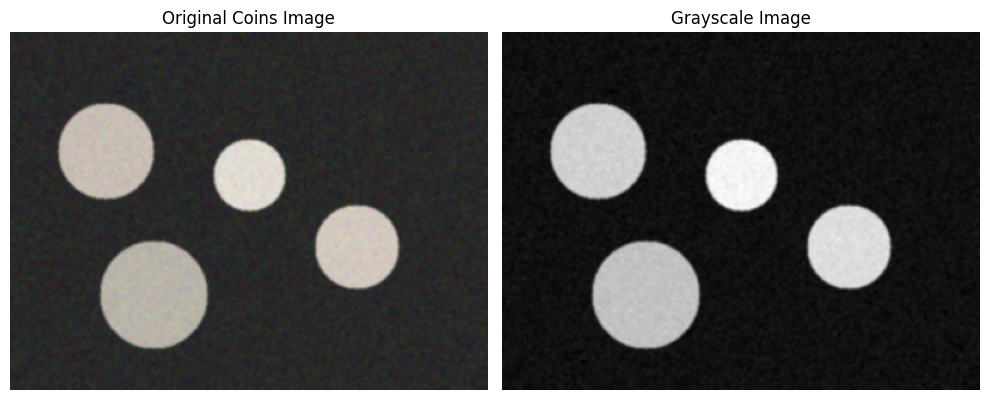

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Clean up any existing broken or empty file
if os.path.exists('coins.jpg'):
    os.remove('coins.jpg')

# Load a sample image using standard wget flags
!wget -q https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/coins.jpg -O coins.jpg
img = cv2.imread('coins.jpg')

# Check if image loaded correctly to prevent assertion errors
if img is None:
    raise FileNotFoundError("Failed to load coins.jpg. Please check the download URL.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def show(images, titles):
    plt.figure(figsize=(5*len(images), 5))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i+1)
        cmap = 'gray' if im.ndim == 2 else None
        plt.imshow(im, cmap=cmap)
        plt.title(t); plt.axis('off')

    plt.show()

## 1. Thresholding
Convert grayscale to binary: pixels >= T become 1 (white), else 0 (black).

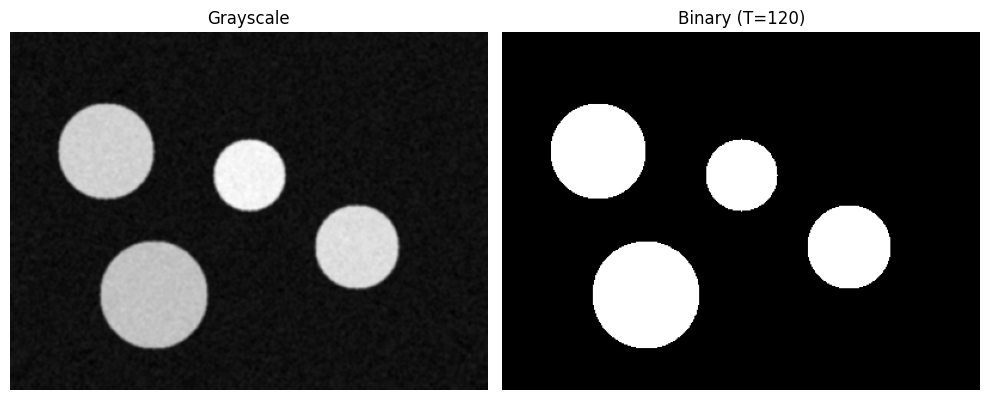

In [9]:
T = 120  # threshold value

_, binary = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY)

show([gray, binary], ['Grayscale', f'Binary (T={T})'])

## 2. Segmentation (simple color-based)
Split the image into regions by color similarity using k-means clustering.

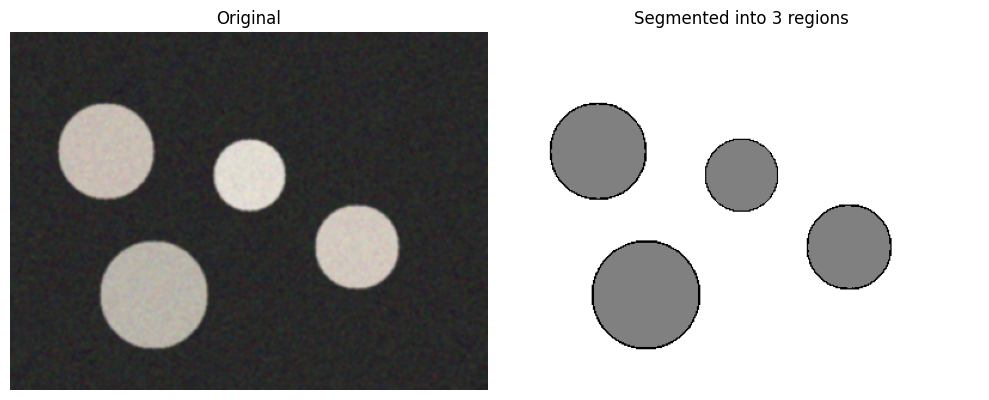

In [10]:
Z = img.reshape((-1, 3)).astype(np.float32)
K = 3  # number of segments

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
_, labels, _ = cv2.kmeans(Z, K, None, criteria, 5, cv2.KMEANS_RANDOM_CENTERS)

segmented = labels.flatten().reshape(img.shape[:2])
show([cv2.cvtColor(img, cv2.COLOR_BGR2RGB), segmented],
     ['Original', f'Segmented into {K} regions'])

## 3. Connected Component Labeling (CCL)
Give every separate white blob its own label (4-connected or 8-connected).

Found 4 objects (8-connected)


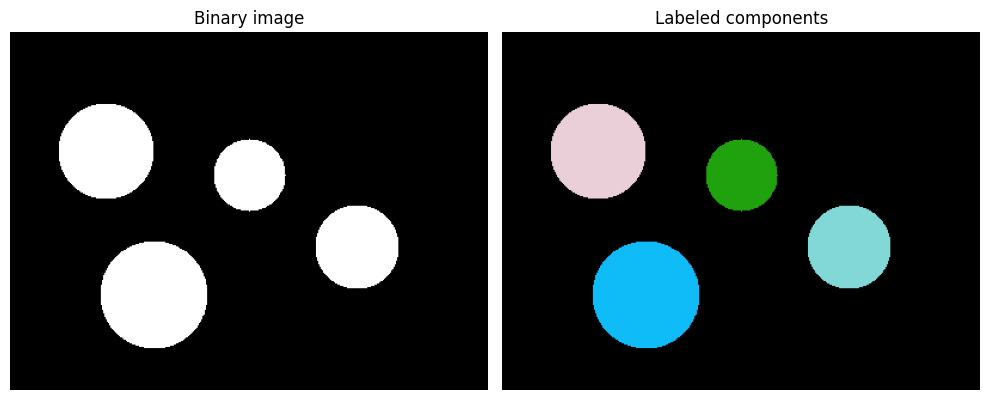

Object 1: area = 5020 px
Object 2: area = 2824 px
Object 3: area = 3849 px
Object 4: area = 6330 px


In [11]:
num, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)

# Color each component a different color
rng = np.random.default_rng(0)
colors = rng.integers(0, 255, size=(num, 3), dtype=np.uint8)
colors[0] = 0  # background stays black
colored = colors[labels]

print(f'Found {num - 1} objects (8-connected)')
show([binary, cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)],
     ['Binary image', 'Labeled components'])

# Object sizes (area of each component in pixels)
for i in range(1, num):
    print(f'Object {i}: area = {stats[i, cv2.CC_STAT_AREA]} px')